In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.patches as mpatches
from scipy.stats import mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [4]:
plt.rcParams['svg.fonttype'] = 'none'

In [5]:
## load the value of median dN/dS of housekeeping genes
hk_df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/housekeeping_dnds.csv")
hk_dnds_Dpse = hk_df['Dpse_dnds'].values
hk_median_Dpse = np.median(hk_dnds_Dpse)

print(hk_median_Dpse)

0.03585


**1. Comparison of dN/dS of tissue-specific genes**

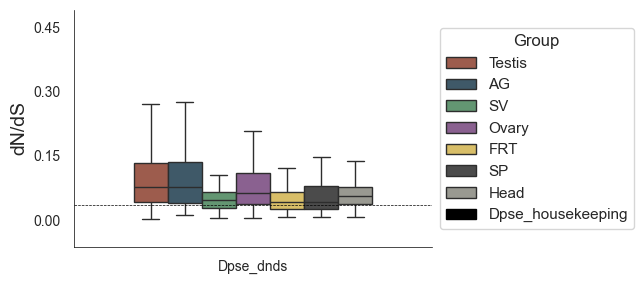

In [3]:
## load dN/dS value
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/tissue_specific_dnds.csv")

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 42 = TrueType 字体，保存为可编辑文字
mpl.rcParams['ps.fonttype'] = 42

df_long = pd.melt(df, id_vars=['Group'], value_vars=['Dpse_dnds'],
                  var_name='Species', value_name='dN/dS')

sns.set(style="whitegrid")

## load housekeeping dN/dS value
custom_colors = [
    "#AA5440",
    "#385B6F",
    "#5A9E6F",
    "#905998",
    "#EBC855",
    "#4B4B4B",
    "#9A9A90"
]

## draw the boxplot for dN/dS
plt.figure(figsize=(6.6, 3))
group_order = df_long['Group'].unique()
ax = sns.boxplot(x='Species', y='dN/dS', hue='Group', data=df_long,
                 hue_order=group_order,
                 palette=custom_colors,
                 showfliers=False,
                 width=0.8)

line_dpse = ax.axhline(hk_median_Dpse, color="black", linestyle="--", linewidth=0.5)

handles, labels = ax.get_legend_handles_labels()

hk_handles = [mpatches.Patch(color="black", label="Dpse_housekeeping")]

plt.legend(handles[:8] + hk_handles, labels[:8] + ["Dpse_housekeeping"],
           title='Group', loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)

plt.ylabel("dN/dS", fontsize=14)
plt.xlabel("", fontsize=0)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

ymin, ymax = plt.ylim()
plt.ylim(ymin - 0.05, ymax + 0.2)
xmin, xmax = plt.xlim()
plt.xlim(xmin - 0.1, xmax + 0.1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_linewidth(0.5)
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_linewidth(0.5)
ax.spines['left'].set_color('black')

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.15))
plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [4]:
# calculate significance
def significance_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

combined_results = []
species_list = df_long['Species'].unique()
group_list = df_long['Group'].unique()

# 1. 循环计算原始 P 值
for sp in species_list:
    # 根据物种选择对应的 Housekeeping 集合
    hk_sample = hk_dnds_Dpse if sp == 'Dpse_dnds' else hk_dnds_Dmel
    hk_median = np.median(hk_sample)
    # 计算四分位距 (IQR) 作为离散程度的度量
    hk_q1, hk_q3 = np.percentile(hk_sample, [25, 75])

    df_sp = df_long[df_long['Species'] == sp]

    # --- 对比 1: 每个 Group vs. Housekeeping ---
    for grp in group_list:
        grp_sample = df_sp[df_sp['Group'] == grp]['dN/dS'].dropna()
        if len(grp_sample) > 0:
            m1 = np.median(grp_sample)
            q1, q3 = np.percentile(grp_sample, [25, 75])

            stat, p_val = mannwhitneyu(grp_sample, hk_sample, alternative='two-sided')

            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp} vs Housekeeping',
                'Val_1': f"{m1:.4f} ({q1:.3f}-{q3:.3f})", # 展示中位数(IQR)
                'Val_2': f"{hk_median:.4f} ({hk_q1:.3f}-{hk_q3:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

    # --- 对比 2: Group 内部两两比较 ---
    for grp1, grp2 in combinations(group_list, 2):
        sample1 = df_sp[df_sp['Group'] == grp1]['dN/dS'].dropna()
        sample2 = df_sp[df_sp['Group'] == grp2]['dN/dS'].dropna()

        if len(sample1) > 0 and len(sample2) > 0:
            m1, q1a, q3a = np.median(sample1), *np.percentile(sample1, [25, 75])
            m2, q1b, q3b = np.median(sample2), *np.percentile(sample2, [25, 75])

            stat, p_val = mannwhitneyu(sample1, sample2, alternative='two-sided')
            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp1} vs {grp2}',
                'Val_1': f"{m1:.4f} ({q1a:.3f}-{q3a:.3f})",
                'Val_2': f"{m2:.4f} ({q1b:.3f}-{q3b:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

# 2. 核心步骤：多重比较校正 (FDR / BH Method)
results_df = pd.DataFrame(combined_results)
if not results_df.empty:
    # 对所有对比产生的 P 值统一进行 BH 校正
    _, p_adj, _, _ = multipletests(results_df['p_raw'], method='fdr_bh')
    results_df['p_adj'] = p_adj
    results_df['significance'] = results_df['p_adj'].apply(significance_stars)

# 3. 格式化输出
final_df = results_df[[
    'Species', 'Comparison',
    'Val_1', 'Val_2',
    'p_raw', 'p_adj', 'significance'
]]

# 为了方便阅读，将极小的 P 值转为科学计数法
final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")

final_df

C:\Users\Administrator\AppData\Local\Temp\ipykernel_28684\45556892.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_28684\45556892.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")


,Species,Comparison,Val_1,Val_2,p_raw,p_adj,significance
0,Dpse_dnds,Testis vs Housekeeping,0.0776 (0.041-0.133),0.0358 (0.016-0.060),0.000,0.000,***
1,Dpse_dnds,AG vs Housekeeping,0.0774 (0.039-0.135),0.0358 (0.016-0.060),0.000,0.000,***
2,Dpse_dnds,SV vs Housekeeping,0.0467 (0.029-0.067),0.0358 (0.016-0.060),0.0088,0.0176,*
3,Dpse_dnds,Ovary vs Housekeeping,0.0622 (0.038-0.110),0.0358 (0.016-0.060),0.000,0.000,***
4,Dpse_dnds,FRT vs Housekeeping,0.0432 (0.026-0.065),0.0358 (0.016-0.060),0.0568,0.0883,ns
5,Dpse_dnds,SP vs Housekeeping,0.0432 (0.026-0.079),0.0358 (0.016-0.060),0.0713,0.1051,ns
6,Dpse_dnds,Head vs Housekeeping,0.0564 (0.037-0.077),0.0358 (0.016-0.060),0.0023,0.0072,**
7,Dpse_dnds,Testis vs AG,0.0776 (0.041-0.133),0.0774 (0.039-0.135),0.9241,0.9241,ns
8,Dpse_dnds,Testis vs SV,0.0776 (0.041-0.133),0.0467 (0.029-0.067),0.000,0.000,***
9,Dpse_dnds,Testis vs Ovary,0.0776 (0.041-0.133),0.0622 (0.038-0.110),0.0150,0.0280,*


In [7]:
# calculation of male-specific vs female-specific
male_groups = ['AG', 'SV','testis']
female_groups = ['FRT', 'spermatheca']

df_long['Sex'] = df_long['Group'].apply(
    lambda x: 'male' if x in male_groups else ('female' if x in female_groups else 'other')
)

df_sex = df_long[df_long['Sex'].isin(['male', 'female'])]

sex_results = []

for sp in df_sex['Species'].unique():
    df_sp = df_sex[df_sex['Species'] == sp]

    male_sample = df_sp[df_sp['Sex'] == 'male']['dN/dS'].dropna()
    female_sample = df_sp[df_sp['Sex'] == 'female']['dN/dS'].dropna()

    if len(male_sample) > 0 and len(female_sample) > 0:
        m1, q1a, q3a = np.median(male_sample), *np.percentile(male_sample, [25, 75])
        m2, q1b, q3b = np.median(female_sample), *np.percentile(female_sample, [25, 75])

        stat, p_val = mannwhitneyu(male_sample, female_sample, alternative='two-sided')

        sex_results.append({
            'Species': sp,
            'Comparison': 'male vs female',
            'Val_1': f"{m1:.4f} ({q1a:.3f}-{q3a:.3f})",
            'Val_2': f"{m2:.4f} ({q1b:.3f}-{q3b:.3f})",
            'p_raw': p_val
        })

sex_df = pd.DataFrame(sex_results)

if not sex_df.empty:
    _, p_adj, _, _ = multipletests(sex_df['p_raw'], method='fdr_bh')
    sex_df['p_adj'] = p_adj
    sex_df['significance'] = sex_df['p_adj'].apply(significance_stars)

sex_df

,Species,Comparison,Val_1,Val_2,p_raw,p_adj,significance
0,Dpse_dnds,male vs female,0.0565 (0.034-0.105),0.0432 (0.026-0.065),0.007619,0.007619,**


**2. Comparison of dN/dS of male-delivered proteins and female response genes**

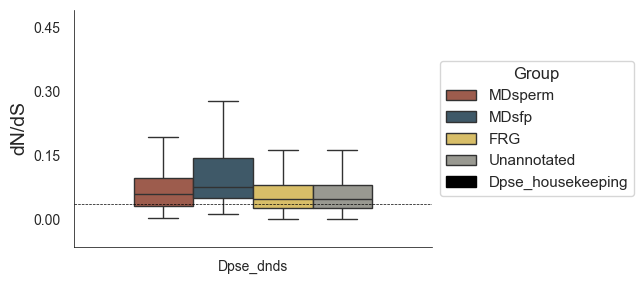

In [5]:
## load dN/dS value
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/MDsperm_MDsfp_FRG_dnds.csv")

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 42 = TrueType 字体，保存为可编辑文字
mpl.rcParams['ps.fonttype'] = 42

df_long = pd.melt(df, id_vars=['Group'], value_vars=['Dpse_dnds'],
                  var_name='Species', value_name='dN/dS')

sns.set(style="whitegrid")

## load housekeeping dN/dS value
custom_colors = [
    "#AA5440",
    "#385B6F",
    "#EBC855",
    "#9A9A90"
]

## draw the boxplot for dN/dS
plt.figure(figsize=(6.6, 3))
group_order = df_long['Group'].unique()
ax = sns.boxplot(x='Species', y='dN/dS', hue='Group', data=df_long,
                 hue_order=group_order,
                 palette=custom_colors,
                 showfliers=False,
                 width=0.8)

line_dpse = ax.axhline(hk_median_Dpse, color="black", linestyle="--", linewidth=0.5)

handles, labels = ax.get_legend_handles_labels()

hk_handles = [mpatches.Patch(color="black", label="Dpse_housekeeping")]

plt.legend(handles[:8] + hk_handles, labels[:8] + ["Dpse_housekeeping"],
           title='Group', loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)

plt.ylabel("dN/dS", fontsize=14)
plt.xlabel("", fontsize=0)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

ymin, ymax = plt.ylim()
plt.ylim(ymin - 0.05, ymax + 0.2)
xmin, xmax = plt.xlim()
plt.xlim(xmin - 0.1, xmax + 0.1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_linewidth(0.5)
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_linewidth(0.5)
ax.spines['left'].set_color('black')

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.15))
plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [6]:
# calculate significance
def significance_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

combined_results = []
species_list = df_long['Species'].unique()
group_list = df_long['Group'].unique()

# 1. 循环计算原始 P 值
for sp in species_list:
    # 根据物种选择对应的 Housekeeping 集合
    hk_sample = hk_dnds_Dpse if sp == 'Dpse_dnds' else hk_dnds_Dmel
    hk_median = np.median(hk_sample)
    # 计算四分位距 (IQR) 作为离散程度的度量
    hk_q1, hk_q3 = np.percentile(hk_sample, [25, 75])

    df_sp = df_long[df_long['Species'] == sp]

    # --- 对比 1: 每个 Group vs. Housekeeping ---
    for grp in group_list:
        grp_sample = df_sp[df_sp['Group'] == grp]['dN/dS'].dropna()
        if len(grp_sample) > 0:
            m1 = np.median(grp_sample)
            q1, q3 = np.percentile(grp_sample, [25, 75])

            stat, p_val = mannwhitneyu(grp_sample, hk_sample, alternative='two-sided')

            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp} vs Housekeeping',
                'Val_1': f"{m1:.4f} ({q1:.3f}-{q3:.3f})", # 展示中位数(IQR)
                'Val_2': f"{hk_median:.4f} ({hk_q1:.3f}-{hk_q3:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

    # --- 对比 2: Group 内部两两比较 ---
    for grp1, grp2 in combinations(group_list, 2):
        sample1 = df_sp[df_sp['Group'] == grp1]['dN/dS'].dropna()
        sample2 = df_sp[df_sp['Group'] == grp2]['dN/dS'].dropna()

        if len(sample1) > 0 and len(sample2) > 0:
            m1, q1a, q3a = np.median(sample1), *np.percentile(sample1, [25, 75])
            m2, q1b, q3b = np.median(sample2), *np.percentile(sample2, [25, 75])

            stat, p_val = mannwhitneyu(sample1, sample2, alternative='two-sided')
            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp1} vs {grp2}',
                'Val_1': f"{m1:.4f} ({q1a:.3f}-{q3a:.3f})",
                'Val_2': f"{m2:.4f} ({q1b:.3f}-{q3b:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

# 2. 核心步骤：多重比较校正 (FDR / BH Method)
results_df = pd.DataFrame(combined_results)
if not results_df.empty:
    # 对所有对比产生的 P 值统一进行 BH 校正
    _, p_adj, _, _ = multipletests(results_df['p_raw'], method='fdr_bh')
    results_df['p_adj'] = p_adj
    results_df['significance'] = results_df['p_adj'].apply(significance_stars)

# 3. 格式化输出
final_df = results_df[[
    'Species', 'Comparison',
    'Val_1', 'Val_2',
    'p_raw', 'p_adj', 'significance'
]]

# 为了方便阅读，将极小的 P 值转为科学计数法
final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")

final_df

C:\Users\Administrator\AppData\Local\Temp\ipykernel_388\45556892.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_388\45556892.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")


,Species,Comparison,Val_1,Val_2,p_raw,p_adj,significance
0,Dpse_dnds,MDsperm vs Housekeeping,0.0596 (0.032-0.097),0.0358 (0.016-0.060),0.000,0.000,***
1,Dpse_dnds,MDsfp vs Housekeeping,0.0768 (0.050-0.145),0.0358 (0.016-0.060),0.000,0.000,***
2,Dpse_dnds,FRG vs Housekeeping,0.0474 (0.028-0.082),0.0358 (0.016-0.060),0.000,0.000,***
3,Dpse_dnds,Unannotated vs Housekeeping,0.0475 (0.027-0.081),0.0358 (0.016-0.060),0.000,0.000,***
4,Dpse_dnds,MDsperm vs MDsfp,0.0596 (0.032-0.097),0.0768 (0.050-0.145),0.0119,0.0132,*
5,Dpse_dnds,MDsperm vs FRG,0.0596 (0.032-0.097),0.0474 (0.028-0.082),0.0035,0.0044,**
6,Dpse_dnds,MDsperm vs Unannotated,0.0596 (0.032-0.097),0.0475 (0.027-0.081),0.0026,0.0037,**
7,Dpse_dnds,MDsfp vs FRG,0.0768 (0.050-0.145),0.0474 (0.028-0.082),0.000,0.000,***
8,Dpse_dnds,MDsfp vs Unannotated,0.0768 (0.050-0.145),0.0475 (0.027-0.081),0.000,0.000,***
9,Dpse_dnds,FRG vs Unannotated,0.0474 (0.028-0.082),0.0475 (0.027-0.081),0.9990,0.9990,ns


**3. Comparison of dN/dS of putative sex peptide (SP) network interacting proteins and other male-delivered proteins**

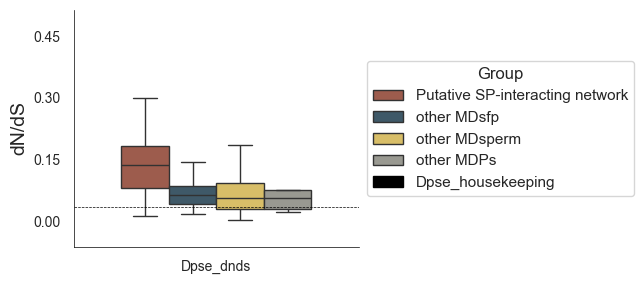

In [8]:
## load dN/dS value
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/SPnetwork_dnds.csv")

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 42 = TrueType 字体，保存为可编辑文字
mpl.rcParams['ps.fonttype'] = 42

df_long = pd.melt(df, id_vars=['Group'], value_vars=['Dpse_dnds'],
                  var_name='Species', value_name='dN/dS')

sns.set(style="whitegrid")

## load housekeeping dN/dS value
custom_colors = [
    "#AA5440",
    "#385B6F",
    "#EBC855",
    "#9a9a90"
]

## draw the boxplot for dN/dS
plt.figure(figsize=(6.6, 3))
group_order = df_long['Group'].unique()
ax = sns.boxplot(x='Species', y='dN/dS', hue='Group', data=df_long,
                 hue_order=group_order,
                 palette=custom_colors,
                 showfliers=False,
                 width=0.8)

line_dpse = ax.axhline(hk_median_Dpse, color="black", linestyle="--", linewidth=0.5)

handles, labels = ax.get_legend_handles_labels()

hk_handles = [mpatches.Patch(color="black", label="Dpse_housekeeping")]

plt.legend(handles[:8] + hk_handles, labels[:8] + ["Dpse_housekeeping"],
           title='Group', loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)

plt.ylabel("dN/dS", fontsize=14)
plt.xlabel("", fontsize=0)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

ymin, ymax = plt.ylim()
plt.ylim(ymin - 0.05, ymax + 0.2)
xmin, xmax = plt.xlim()
plt.xlim(xmin - 0.1, xmax + 0.1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_linewidth(0.5)
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_linewidth(0.5)
ax.spines['left'].set_color('black')

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.15))
plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/2026.4 new/Sperm_associated_SFP_dnds.svg", dpi=300, bbox_inches='tight')
plt.show()

In [9]:
# calculate significance
def significance_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

combined_results = []
species_list = df_long['Species'].unique()
group_list = df_long['Group'].unique()

# 1. 循环计算原始 P 值
for sp in species_list:
    # 根据物种选择对应的 Housekeeping 集合
    hk_sample = hk_dnds_Dpse if sp == 'Dpse_dnds' else hk_dnds_Dmel
    hk_median = np.median(hk_sample)
    # 计算四分位距 (IQR) 作为离散程度的度量
    hk_q1, hk_q3 = np.percentile(hk_sample, [25, 75])

    df_sp = df_long[df_long['Species'] == sp]

    # --- 对比 1: 每个 Group vs. Housekeeping ---
    for grp in group_list:
        grp_sample = df_sp[df_sp['Group'] == grp]['dN/dS'].dropna()
        if len(grp_sample) > 0:
            m1 = np.median(grp_sample)
            q1, q3 = np.percentile(grp_sample, [25, 75])

            stat, p_val = mannwhitneyu(grp_sample, hk_sample, alternative='two-sided')

            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp} vs Housekeeping',
                'Val_1': f"{m1:.4f} ({q1:.3f}-{q3:.3f})", # 展示中位数(IQR)
                'Val_2': f"{hk_median:.4f} ({hk_q1:.3f}-{hk_q3:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

    # --- 对比 2: Group 内部两两比较 ---
    for grp1, grp2 in combinations(group_list, 2):
        sample1 = df_sp[df_sp['Group'] == grp1]['dN/dS'].dropna()
        sample2 = df_sp[df_sp['Group'] == grp2]['dN/dS'].dropna()

        if len(sample1) > 0 and len(sample2) > 0:
            m1, q1a, q3a = np.median(sample1), *np.percentile(sample1, [25, 75])
            m2, q1b, q3b = np.median(sample2), *np.percentile(sample2, [25, 75])

            stat, p_val = mannwhitneyu(sample1, sample2, alternative='two-sided')
            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp1} vs {grp2}',
                'Val_1': f"{m1:.4f} ({q1a:.3f}-{q3a:.3f})",
                'Val_2': f"{m2:.4f} ({q1b:.3f}-{q3b:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

# 2. 核心步骤：多重比较校正 (FDR / BH Method)
results_df = pd.DataFrame(combined_results)
if not results_df.empty:
    # 对所有对比产生的 P 值统一进行 BH 校正
    _, p_adj, _, _ = multipletests(results_df['p_raw'], method='fdr_bh')
    results_df['p_adj'] = p_adj
    results_df['significance'] = results_df['p_adj'].apply(significance_stars)

# 3. 格式化输出
final_df = results_df[[
    'Species', 'Comparison',
    'Val_1', 'Val_2',
    'p_raw', 'p_adj', 'significance'
]]

# 为了方便阅读，将极小的 P 值转为科学计数法
final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")

final_df

C:\Users\Administrator\AppData\Local\Temp\ipykernel_35888\45556892.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_35888\45556892.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")


,Species,Comparison,Val_1,Val_2,p_raw,p_adj,significance
0,Dpse_dnds,Putative SP-interacting network vs Housekeeping,0.1371 (0.082-0.183),0.0358 (0.016-0.060),0.000,0.000,***
1,Dpse_dnds,other MDsfp vs Housekeeping,0.0644 (0.042-0.086),0.0358 (0.016-0.060),0.0013,0.0033,**
2,Dpse_dnds,other MDsperm vs Housekeeping,0.0564 (0.031-0.093),0.0358 (0.016-0.060),0.000,0.000,***
3,Dpse_dnds,other MDPs vs Housekeeping,0.0577 (0.030-0.078),0.0358 (0.016-0.060),0.1795,0.2992,ns
4,Dpse_dnds,Putative SP-interacting network vs other MDsfp,0.1371 (0.082-0.183),0.0644 (0.042-0.086),0.0029,0.0057,**
5,Dpse_dnds,Putative SP-interacting network vs other MDsperm,0.1371 (0.082-0.183),0.0564 (0.031-0.093),0.000,0.000,***
6,Dpse_dnds,Putative SP-interacting network vs other MDPs,0.1371 (0.082-0.183),0.0577 (0.030-0.078),0.2268,0.3240,ns
7,Dpse_dnds,other MDsfp vs other MDsperm,0.0644 (0.042-0.086),0.0564 (0.031-0.093),0.5566,0.6958,ns
8,Dpse_dnds,other MDsfp vs other MDPs,0.0644 (0.042-0.086),0.0577 (0.030-0.078),1.0000,1.0000,ns
9,Dpse_dnds,other MDsperm vs other MDPs,0.0564 (0.031-0.093),0.0577 (0.030-0.078),0.9657,1.0000,ns


**4. Comparison of dN/dS of sperm-associated SFPs (Overlap) and sperm-non-associated (Non-overlap) SFPs**

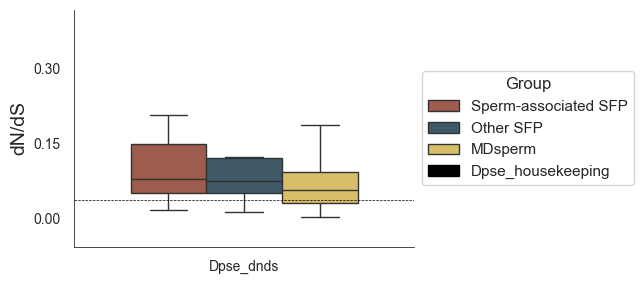

In [9]:
## load dN/dS value
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/Overlapping_MDP_dnds.csv")

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 42 = TrueType 字体，保存为可编辑文字
mpl.rcParams['ps.fonttype'] = 42

df_long = pd.melt(df, id_vars=['Group'], value_vars=['Dpse_dnds'],
                  var_name='Species', value_name='dN/dS')

sns.set(style="whitegrid")

## load housekeeping dN/dS value
custom_colors = [
    "#AA5440",
    "#385B6F",
    "#EBC855"
]

## draw the boxplot for dN/dS
plt.figure(figsize=(6.6, 3))
group_order = df_long['Group'].unique()
ax = sns.boxplot(x='Species', y='dN/dS', hue='Group', data=df_long,
                 hue_order=group_order,
                 palette=custom_colors,
                 showfliers=False,
                 width=0.8)

line_dpse = ax.axhline(hk_median_Dpse, color="black", linestyle="--", linewidth=0.5)

handles, labels = ax.get_legend_handles_labels()

hk_handles = [mpatches.Patch(color="black", label="Dpse_housekeeping")]

plt.legend(handles[:8] + hk_handles, labels[:8] + ["Dpse_housekeeping"],
           title='Group', loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)

plt.ylabel("dN/dS", fontsize=14)
plt.xlabel("", fontsize=0)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

ymin, ymax = plt.ylim()
plt.ylim(ymin - 0.05, ymax + 0.2)
xmin, xmax = plt.xlim()
plt.xlim(xmin - 0.1, xmax + 0.1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_linewidth(0.5)
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_linewidth(0.5)
ax.spines['left'].set_color('black')

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.15))
plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/2026.4 new/Sperm_associated_SFP_dnds.svg", dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# calculate significance
def significance_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

combined_results = []
species_list = df_long['Species'].unique()
group_list = df_long['Group'].unique()

# 1. 循环计算原始 P 值
for sp in species_list:
    # 根据物种选择对应的 Housekeeping 集合
    hk_sample = hk_dnds_Dpse if sp == 'Dpse_dnds' else hk_dnds_Dmel
    hk_median = np.median(hk_sample)
    # 计算四分位距 (IQR) 作为离散程度的度量
    hk_q1, hk_q3 = np.percentile(hk_sample, [25, 75])

    df_sp = df_long[df_long['Species'] == sp]

    # --- 对比 1: 每个 Group vs. Housekeeping ---
    for grp in group_list:
        grp_sample = df_sp[df_sp['Group'] == grp]['dN/dS'].dropna()
        if len(grp_sample) > 0:
            m1 = np.median(grp_sample)
            q1, q3 = np.percentile(grp_sample, [25, 75])

            stat, p_val = mannwhitneyu(grp_sample, hk_sample, alternative='two-sided')

            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp} vs Housekeeping',
                'Val_1': f"{m1:.4f} ({q1:.3f}-{q3:.3f})", # 展示中位数(IQR)
                'Val_2': f"{hk_median:.4f} ({hk_q1:.3f}-{hk_q3:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

    # --- 对比 2: Group 内部两两比较 ---
    for grp1, grp2 in combinations(group_list, 2):
        sample1 = df_sp[df_sp['Group'] == grp1]['dN/dS'].dropna()
        sample2 = df_sp[df_sp['Group'] == grp2]['dN/dS'].dropna()

        if len(sample1) > 0 and len(sample2) > 0:
            m1, q1a, q3a = np.median(sample1), *np.percentile(sample1, [25, 75])
            m2, q1b, q3b = np.median(sample2), *np.percentile(sample2, [25, 75])

            stat, p_val = mannwhitneyu(sample1, sample2, alternative='two-sided')
            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp1} vs {grp2}',
                'Val_1': f"{m1:.4f} ({q1a:.3f}-{q3a:.3f})",
                'Val_2': f"{m2:.4f} ({q1b:.3f}-{q3b:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

# 2. 核心步骤：多重比较校正 (FDR / BH Method)
results_df = pd.DataFrame(combined_results)
if not results_df.empty:
    # 对所有对比产生的 P 值统一进行 BH 校正
    _, p_adj, _, _ = multipletests(results_df['p_raw'], method='fdr_bh')
    results_df['p_adj'] = p_adj
    results_df['significance'] = results_df['p_adj'].apply(significance_stars)

# 3. 格式化输出
final_df = results_df[[
    'Species', 'Comparison',
    'Val_1', 'Val_2',
    'p_raw', 'p_adj', 'significance'
]]

# 为了方便阅读，将极小的 P 值转为科学计数法
final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")

final_df

C:\Users\Administrator\AppData\Local\Temp\ipykernel_30208\45556892.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_30208\45556892.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")


,Species,Comparison,Val_1,Val_2,p_raw,p_adj,significance
0,Dpse_dnds,Sperm-associated SFP vs Housekeeping,0.0785 (0.050-0.148),0.0358 (0.016-0.060),0.000,0.000,***
1,Dpse_dnds,Other SFP vs Housekeeping,0.0745 (0.050-0.120),0.0358 (0.016-0.060),0.001,0.0016,**
2,Dpse_dnds,MDsperm vs Housekeeping,0.0564 (0.031-0.093),0.0358 (0.016-0.060),0.000,0.000,***
3,Dpse_dnds,Sperm-associated SFP vs Other SFP,0.0785 (0.050-0.148),0.0745 (0.050-0.120),0.9015,0.9015,ns
4,Dpse_dnds,Sperm-associated SFP vs MDsperm,0.0785 (0.050-0.148),0.0564 (0.031-0.093),0.0176,0.0263,*
5,Dpse_dnds,Other SFP vs MDsperm,0.0745 (0.050-0.120),0.0564 (0.031-0.093),0.0726,0.0871,ns


**5. Comparison of dN/dS of key male-delivered proteins and other male-delivered (MD) proteins**

C:\Users\Administrator\AppData\Local\Temp\ipykernel_46800\642509628.py:24: UserWarning: The palette list has more values (4) than needed (2), which may not be intended.
  ax = sns.boxplot(x='Species', y='dN/dS', hue='Group', data=df_long,


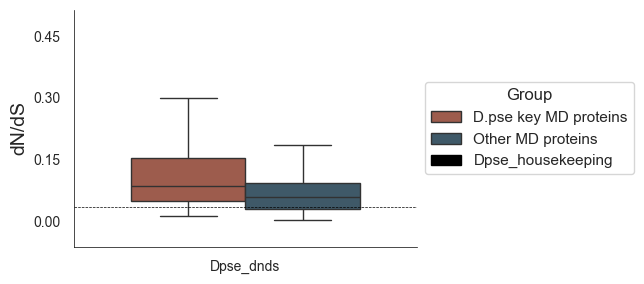

In [6]:
## load dN/dS value
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/SPnetwork_dnds - 副本.csv")

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 42 = TrueType 字体，保存为可编辑文字
mpl.rcParams['ps.fonttype'] = 42

df_long = pd.melt(df, id_vars=['Group'], value_vars=['Dpse_dnds'],
                  var_name='Species', value_name='dN/dS')

sns.set(style="whitegrid")

## load housekeeping dN/dS value
custom_colors = [
    "#AA5440",
    "#385B6F",
    "#EBC855",
    "#9A9A90"
]

## draw the boxplot for dN/dS
plt.figure(figsize=(6.6, 3))
group_order = df_long['Group'].unique()
ax = sns.boxplot(x='Species', y='dN/dS', hue='Group', data=df_long,
                 hue_order=group_order,
                 palette=custom_colors,
                 showfliers=False,
                 width=0.8)

line_dpse = ax.axhline(hk_median_Dpse, color="black", linestyle="--", linewidth=0.5)

handles, labels = ax.get_legend_handles_labels()

hk_handles = [mpatches.Patch(color="black", label="Dpse_housekeeping")]

plt.legend(handles[:8] + hk_handles, labels[:8] + ["Dpse_housekeeping"],
           title='Group', loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)

plt.ylabel("dN/dS", fontsize=14)
plt.xlabel("", fontsize=0)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

ymin, ymax = plt.ylim()
plt.ylim(ymin - 0.05, ymax + 0.2)
xmin, xmax = plt.xlim()
plt.xlim(xmin - 0.1, xmax + 0.1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)

ax.spines['bottom'].set_linewidth(0.5)
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_linewidth(0.5)
ax.spines['left'].set_color('black')

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.15))
plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/2026.4 new/SPnetwork2.svg", dpi=300, bbox_inches='tight')
plt.show()

In [7]:
# calculate significance
def significance_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

combined_results = []
species_list = df_long['Species'].unique()
group_list = df_long['Group'].unique()

# 1. 循环计算原始 P 值
for sp in species_list:
    # 根据物种选择对应的 Housekeeping 集合
    hk_sample = hk_dnds_Dpse if sp == 'Dpse_dnds' else hk_dnds_Dmel
    hk_median = np.median(hk_sample)
    # 计算四分位距 (IQR) 作为离散程度的度量
    hk_q1, hk_q3 = np.percentile(hk_sample, [25, 75])

    df_sp = df_long[df_long['Species'] == sp]

    # --- 对比 1: 每个 Group vs. Housekeeping ---
    for grp in group_list:
        grp_sample = df_sp[df_sp['Group'] == grp]['dN/dS'].dropna()
        if len(grp_sample) > 0:
            m1 = np.median(grp_sample)
            q1, q3 = np.percentile(grp_sample, [25, 75])

            stat, p_val = mannwhitneyu(grp_sample, hk_sample, alternative='two-sided')

            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp} vs Housekeeping',
                'Val_1': f"{m1:.4f} ({q1:.3f}-{q3:.3f})", # 展示中位数(IQR)
                'Val_2': f"{hk_median:.4f} ({hk_q1:.3f}-{hk_q3:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

    # --- 对比 2: Group 内部两两比较 ---
    for grp1, grp2 in combinations(group_list, 2):
        sample1 = df_sp[df_sp['Group'] == grp1]['dN/dS'].dropna()
        sample2 = df_sp[df_sp['Group'] == grp2]['dN/dS'].dropna()

        if len(sample1) > 0 and len(sample2) > 0:
            m1, q1a, q3a = np.median(sample1), *np.percentile(sample1, [25, 75])
            m2, q1b, q3b = np.median(sample2), *np.percentile(sample2, [25, 75])

            stat, p_val = mannwhitneyu(sample1, sample2, alternative='two-sided')
            combined_results.append({
                'Species': sp,
                'Comparison': f'{grp1} vs {grp2}',
                'Val_1': f"{m1:.4f} ({q1a:.3f}-{q3a:.3f})",
                'Val_2': f"{m2:.4f} ({q1b:.3f}-{q3b:.3f})",
                'U_stat': stat,
                'p_raw': p_val
            })

# 2. 核心步骤：多重比较校正 (FDR / BH Method)
results_df = pd.DataFrame(combined_results)
if not results_df.empty:
    # 对所有对比产生的 P 值统一进行 BH 校正
    _, p_adj, _, _ = multipletests(results_df['p_raw'], method='fdr_bh')
    results_df['p_adj'] = p_adj
    results_df['significance'] = results_df['p_adj'].apply(significance_stars)

# 3. 格式化输出
final_df = results_df[[
    'Species', 'Comparison',
    'Val_1', 'Val_2',
    'p_raw', 'p_adj', 'significance'
]]

# 为了方便阅读，将极小的 P 值转为科学计数法
final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")

final_df

C:\Users\Administrator\AppData\Local\Temp\ipykernel_46800\45556892.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_raw'] = final_df['p_raw'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_46800\45556892.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['p_adj'] = final_df['p_adj'].apply(lambda x: f"{x:.3f}" if x < 0.001 else f"{x:.4f}")


,Species,Comparison,Val_1,Val_2,p_raw,p_adj,significance
0,Dpse_dnds,D.pse key MD proteins vs Housekeeping,0.0857 (0.049-0.154),0.0358 (0.016-0.060),0.000,0.000,***
1,Dpse_dnds,Other MD proteins vs Housekeeping,0.0591 (0.031-0.094),0.0358 (0.016-0.060),0.000,0.000,***
2,Dpse_dnds,D.pse key MD proteins vs Other MD proteins,0.0857 (0.049-0.154),0.0591 (0.031-0.094),0.0106,0.0106,*
